# 01 - MVTec AD exploration (Day 2)
**Rule for today:** no modeling code. Answer the questions below with numbers, then write your findings in the markdown cells.

Questions:
1. What categories exist, and which are textures vs objects?
2. Good vs defective counts per category, per split
3. Which defect types exist per category, and how many samples each?
4. Image resolutions and color modes
5. Does every defective image have a ground-truth mask? How big are the defects?
6. **The design question:** train has only good images. Where will the VLM's defective training examples come from?

In [1]:
import os, re
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 200)

# Find the dataset root instead of hardcoding it: Kaggle mount paths vary
candidates = [p.parent for p in Path('/kaggle/input').rglob('bottle') if p.is_dir() and (p / 'train').exists()]
assert candidates, 'MVTec AD not found - did you attach it via Add Input?'
ROOT = candidates[0]
print('ROOT =', ROOT)
print(sorted(os.listdir(ROOT)))

ROOT = /kaggle/input/datasets/ipythonx/mvtec-ad
['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'license.txt', 'metal_nut', 'pill', 'readme.txt', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


## Step 1 - Build a manifest (one row per image)
This DataFrame becomes the input to the Week 1 data pipeline, so get it right.

In [2]:
TEXTURES = {'carpet', 'grid', 'leather', 'tile', 'wood','toothbrush'}
IMG_EXT = {'.png', '.jpg', '.jpeg'}
rows = []
for cat_dir in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    cat = cat_dir.name
    for split in ['train', 'test']:
        split_dir = cat_dir / split
        if not split_dir.exists():
            continue
        for dtype_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            dtype = dtype_dir.name
            for img in sorted(dtype_dir.iterdir()):
                if img.suffix.lower() not in IMG_EXT:
                    continue
                mask = cat_dir / 'ground_truth' / dtype / f'{img.stem}_mask.png'
                rows.append(dict(
                    category=cat,
                    kind='texture' if cat in TEXTURES else 'object',
                    split=split,
                    defect_type=dtype,
                    label='good' if dtype == 'good' else 'defect',
                    path=str(img),
                    mask_path=str(mask) if dtype != 'good' else None,
                    mask_exists=mask.exists() if dtype != 'good' else None,
                ))
df = pd.DataFrame(rows)
print(len(df), 'images')   # expected: 5354 (3629 train + 1725 test)
df.head()

5354 images


,category,kind,split,defect_type,label,path,mask_path,mask_exists
0,bottle,object,train,good,good,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,None,None
1,bottle,object,train,good,good,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,None,None
2,bottle,object,train,good,good,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,None,None
3,bottle,object,train,good,good,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,None,None
4,bottle,object,train,good,good,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,None,None


## Q1 + Q2 - Categories and good/defect counts

In [3]:
counts = df.pivot_table(index=['kind', 'category'], columns=['split', 'label'],
                        values='path', aggfunc='count', fill_value=0)
counts['defect_ratio_test'] = (counts[('test', 'defect')] /
                               (counts[('test', 'defect')] + counts[('test', 'good')])).round(2)
counts

split                test      train defect_ratio_test
label              defect good  good                  
kind    category                                      
object  bottle         63   20   209              0.76
        cable          92   58   224              0.61
        capsule       109   23   219              0.83
        hazelnut       70   40   391              0.64
        metal_nut      93   22   220              0.81
        pill          141   26   267              0.84
        screw         119   41   320              0.74
        transistor     40   60   213              0.40
        zipper        119   32   240              0.79
texture carpet         89   28   280              0.76
        grid           57   21   264              0.73
        leather        92   32   245              0.74
        tile           84   33   230              0.72
        toothbrush     30   12    60              0.71
        wood           60   19   247              0.76

In [4]:
# Sanity check: is there ANY defect in train?
print(df[(df.split == 'train') & (df.label == 'defect')].shape[0], 'defective images in train')

0 defective images in train


In [5]:
   df[df.split=='train'].label.value_counts(normalize=True)

label
good    1.0
Name: proportion, dtype: float64

## Q3 - Defect types per category

In [6]:
dt = (df[df.label == 'defect']
      .groupby(['category', 'defect_type']).size()
      .rename('n').reset_index())
print(dt.defect_type.nunique(), 'unique (category, type) names;',
      len(dt), 'category-type pairs')   # papers report ~73 types
dt.sort_values('n').head(15)   # the rarest classes - these will hurt fine-tuning

48 unique (category, type) names; 73 category-type pairs


,category,defect_type,n
61,wood,color,8
44,pill,pill_type,9
7,cable,cut_outer_insulation,10
9,cable,missing_wire,10
60,transistor,misplaced,10
63,wood,hole,10
10,cable,poke_insulation,10
59,transistor,damaged_case,10
57,transistor,bent_lead,10
58,transistor,cut_lead,10


In [7]:
dt.pivot(index='category', columns='defect_type', values='n').fillna(0).astype(int)

defect_type,bent,bent_lead,bent_wire,broken,broken_large,broken_small,broken_teeth,cable_swap,color,combined,...,rough,scratch,scratch_head,scratch_neck,split_teeth,squeeze,squeezed_teeth,thread,thread_side,thread_top
category,,,,,,,,,,,,,,,,,,,,,
bottle,0,0,0,0,20,22,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
cable,0,0,13,0,0,0,0,12,0,11,...,0,0,0,0,0,0,0,0,0,0
capsule,0,0,0,0,0,0,0,0,0,0,...,0,23,0,0,0,20,0,0,0,0
carpet,0,0,0,0,0,0,0,0,19,0,...,0,0,0,0,0,0,0,19,0,0
grid,12,0,0,12,0,0,0,0,0,0,...,0,0,0,0,0,0,0,11,0,0
hazelnut,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
leather,0,0,0,0,0,0,0,0,19,0,...,0,0,0,0,0,0,0,0,0,0
metal_nut,25,0,0,0,0,0,0,0,22,0,...,0,23,0,0,0,0,0,0,0,0
pill,0,0,0,0,0,0,0,0,25,17,...,0,24,0,0,0,0,0,0,0,0


**Findings Q3:** Which pairs have under ~15 samples? What does that mean for a train/val/test split *inside* the test set?
- 

## Q4 - Resolution and color mode (header read only, fast)

In [8]:
def meta(p):
    with Image.open(p) as im:
        return im.size[0], im.size[1], im.mode
df[['w', 'h', 'mode']] = pd.DataFrame(df.path.map(meta).tolist(), index=df.index)
df.groupby('category')[['w', 'h', 'mode']].agg(lambda s: sorted(set(s)))

,w,h,mode
category,,,
bottle,[900],[900],[RGB]
cable,[1024],[1024],[RGB]
capsule,[1000],[1000],[RGB]
carpet,[1024],[1024],[RGB]
grid,[1024],[1024],[L]
hazelnut,[1024],[1024],[RGB]
leather,[1024],[1024],[RGB]
metal_nut,[700],[700],[RGB]
pill,[800],[800],[RGB]


**Findings Q4:** Which categories are grayscale? Qwen2-VL resizes images to patches - what fine detail might you lose at the resolution you'll feed it?
- 

## Q5 - Mask coverage and defect size

In [9]:
d = df[df.label == 'defect'].copy()
   print('Missing masks:', (d.mask_exists == False).sum())
def mask_frac(p):
    m = np.array(Image.open(p).convert('L')) > 0
    return m.mean()
d['defect_area_frac'] = d.mask_path.map(mask_frac)
d.groupby('category').defect_area_frac.describe()[['min', '50%', 'max']].round(4)

Missing masks: 0


,min,50%,max
category,,,
bottle,0.0058,0.0572,0.2742
cable,0.0014,0.0368,0.2258
capsule,0.0004,0.0043,0.0808
carpet,0.0016,0.0148,0.0802
grid,0.0019,0.0060,0.0358
hazelnut,0.0023,0.0162,0.2766
leather,0.0009,0.0046,0.0686
metal_nut,0.0044,0.0367,0.4872
pill,0.0005,0.0103,0.4100


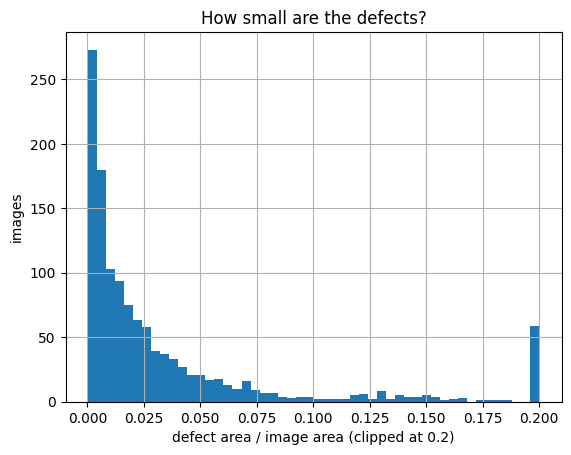

Share of defects under 1% of the image: 0.397


In [10]:
d.defect_area_frac.clip(upper=0.2).hist(bins=50)
plt.xlabel('defect area / image area (clipped at 0.2)'); plt.ylabel('images')
plt.title('How small are the defects?'); plt.show()
print('Share of defects under 1% of the image:', round((d.defect_area_frac < 0.01).mean(), 3))

**Findings Q5:** Tiny defects are the likely failure mode for a 2B VLM. Note the categories where the median is under 1% - they are your Week 3 failure taxonomy candidates.
- 

## Look at the data - one good vs one defect per category

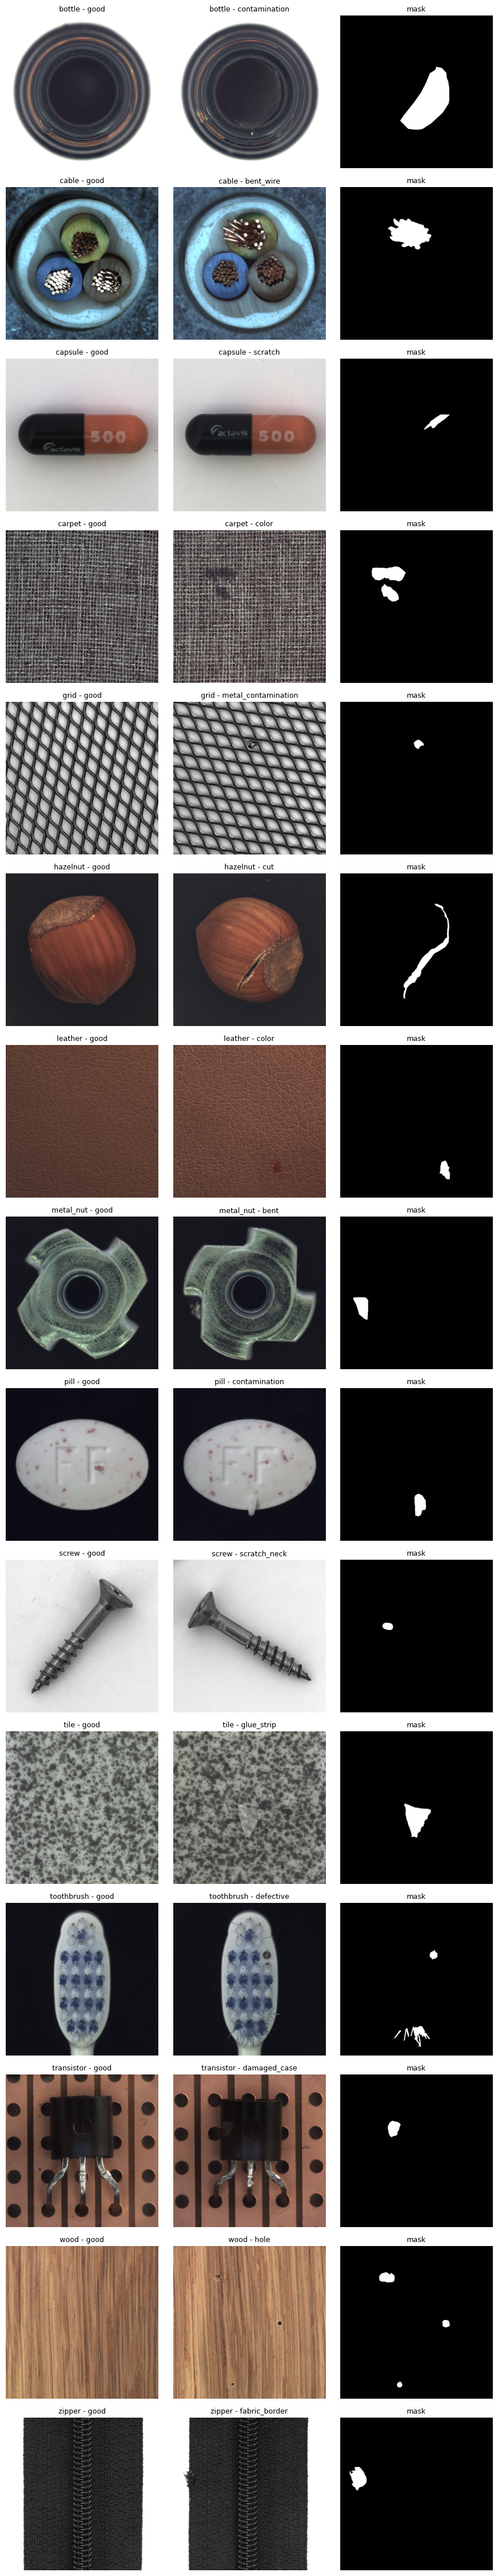

In [10]:
cats = sorted(df.category.unique())
fig, axes = plt.subplots(len(cats), 3, figsize=(9, 3 * len(cats)))
for i, c in enumerate(cats):
    g = df[(df.category == c) & (df.label == 'good')].iloc[0]
    b = d[d.category == c].sample(1, random_state=0).iloc[0]
    for ax, p, t in [(axes[i, 0], g.path, f'{c} - good'),
                     (axes[i, 1], b.path, f'{c} - {b.defect_type}'),
                     (axes[i, 2], b.mask_path, 'mask')]:
        ax.imshow(Image.open(p), cmap='gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## Q6 - The design question (answer this before Day 3)
Train contains only good images. PatchCore is fine with that. The VLM is not.

Answer in writing:
- Which images will the VLM fine-tune on, and which will you evaluate on?
- How do you stop the **same images** from leaking between fine-tune and evaluation?
- Is the split stratified by (category, defect_type)? What happens to rare types?
- Will PatchCore and the VLM be evaluated on the **identical** held-out images? If not, the benchmark is meaningless.

**Your answer:**
- 

In [ ]:
# Save the manifest - this is the Week 1 pipeline input
df.to_csv('/kaggle/working/mvtec_manifest.csv', index=False)
print('saved', len(df), 'rows')